<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS11/JS11-TugasLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Convolutional Neural Network (CNN) - Tugas Lab**

---

> **Tugas Lab CNN:**
>
> 1. **Tugas 1:** Modifikasi model CNN pada Lab 2 (CIFAR-10) sehingga didapatkan akurasi testing **lebih dari 80%**.
> 2. **Tugas 2:** Buat model CNN untuk klasifikasi dataset **MNIST** (digit 0-9).

---

# **Tugas 1 - Modifikasi CNN CIFAR-10 (Akurasi > 80%)**

---

> **Deskripsi Tugas 1:**
>
> Modifikasi arsitektur CNN pada Lab 2 dengan menambahkan lebih banyak layer konvolusi, Batch Normalization, Dropout, dan data augmentation sehingga akurasi testing pada dataset CIFAR-10 melebihi 80%.

---

# **T1 - Langkah 1 - Load Library**

---

> Import library yang dibutuhkan: TensorFlow/Keras untuk perancangan dan pelatihan CNN, layer konvolusi, Batch Normalization, Dropout, augmentasi citra, optimizer Adam, callback ReduceLROnPlateau dan EarlyStopping, serta Matplotlib dan NumPy.

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                      Dropout, BatchNormalization,
                                      RandomFlip, RandomRotation, RandomZoom)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import matplotlib.pyplot as plt
import numpy as np

> Library berhasil diimpor. Seluruh komponen siap digunakan untuk membangun pipeline data, arsitektur CNN, proses pelatihan adaptif, dan evaluasi performa model.

---

# **T1 - Langkah 2 - Persiapan Dataset CIFAR-10**

---

> Load dataset CIFAR-10, lakukan normalisasi nilai piksel ke rentang [0, 1], dan susun pipeline data menggunakan `tf.data.Dataset` dengan `batch_size = 128` serta `prefetch` untuk pemrosesan batch yang optimal.

In [2]:
# Load dan normalisasi dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images = train_images.astype("float32") / 255.0
test_images  = test_images.astype("float32")  / 255.0

# Pipeline tf.data untuk efisiensi pemrosesan batch
BATCH_SIZE = 128
AUTOTUNE   = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((train_images, train_labels))
    .shuffle(10000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((test_images, test_labels))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print(f"Train batches : {len(train_ds)} ({BATCH_SIZE} gambar/batch)")
print(f"Test batches  : {len(test_ds)}")
print(f"Shape gambar  : {train_images.shape[1:]}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 638s 4us/step
Train batches : 391 (128 gambar/batch)
Test batches  : 79
Shape gambar  : (32, 32, 3)


> Dataset CIFAR-10 berhasil dimuat dan dinormalisasi. Pipeline `tf.data` membagi 50.000 data training ke dalam batch-batch berukuran 128 dengan pengacakan, serta 10.000 data testing untuk evaluasi model.

---

# **T1 - Langkah 3 - Bangun Arsitektur CNN yang Lebih Dalam**

---

> Bangun arsitektur CNN yang lebih dalam dengan 3 blok konvolusi (masing-masing 2 layer Conv2D dengan Batch Normalization dan MaxPooling), layer augmentasi citra di awal, serta Fully Connected block dengan Dropout untuk mencegah overfitting.

In [3]:
# Layer augmentasi citra
data_augmentation = models.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.05),
    RandomZoom(0.05),
], name="data_augmentation")

# Arsitektur CNN bertingkat (VGG-style: 2 Conv per blok)
model_improved = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Blok Konvolusi 1
    Conv2D(32, (3,3), activation="relu", padding="same"),
    BatchNormalization(),
    Conv2D(32, (3,3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.2),

    # Blok Konvolusi 2
    Conv2D(64, (3,3), activation="relu", padding="same"),
    BatchNormalization(),
    Conv2D(64, (3,3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),

    # Blok Konvolusi 3
    Conv2D(128, (3,3), activation="relu", padding="same"),
    BatchNormalization(),
    Conv2D(128, (3,3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.4),

    # Fully Connected Block
    Flatten(),
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

model_improved.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

> Ringkasan arsitektur model menampilkan struktur layer lengkap beserta output shape dan jumlah parameter trainable pada setiap layer konvolusi, batch normalization, dan fully connected.

---

# **T1 - Langkah 4 - Kompilasi dan Training**

---

> Kompilasi model dengan optimizer Adam (learning rate 0.001) dan fungsi loss `sparse_categorical_crossentropy`. Pelatihan menggunakan callback `ReduceLROnPlateau` untuk adaptasi learning rate dan `EarlyStopping` untuk memulihkan bobot terbaik saat konvergensi tercapai.

In [4]:
model_improved.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Callback penyesuaian learning rate saat konvergensi melambat
reduce_lr = ReduceLROnPlateau(
    monitor="val_accuracy", factor=0.5,
    patience=3, min_lr=1e-6, verbose=1
)

# Callback penghentian dini dan pemulihan bobot model terbaik
early_stop = EarlyStopping(
    monitor="val_accuracy", patience=6,
    restore_best_weights=True, verbose=1
)

# Pelatihan model
history_imp = model_improved.fit(
    train_ds,
    epochs=25,
    validation_data=test_ds,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 23s 34ms/step - accuracy: 0.3987 - loss: 1.7941 - val_accuracy: 0.2684 - val_loss: 2.3976 - learning_rate: 0.0010
Epoch 2/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.5448 - loss: 1.2684 - val_accuracy: 0.5669 - val_loss: 1.2906 - learning_rate: 0.0010
Epoch 3/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.6127 - loss: 1.0955 - val_accuracy: 0.6380 - val_loss: 1.0677 - learning_rate: 0.0010
Epoch 4/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.6539 - loss: 0.9816 - val_accuracy: 0.6897 - val_loss: 0.8787 - learning_rate: 0.0010
Epoch 5/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.6839 - loss: 0.8989 - val_accuracy: 0.5962 - val_loss: 1.2193 - learning_rate: 0.0010
Epoch 6/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7066 - loss: 0.8393 - val_accuracy: 0.7256 - val_loss: 0.7821 - learning_rate: 0.0010
Epoch 7/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7211 - l

> Pelatihan model selesai. Objek `history_imp` menyimpan nilai loss dan accuracy untuk data training dan validasi di setiap epoch yang dijalankan.

---

# **T1 - Langkah 5 - Evaluasi Model yang Dimodifikasi**

---

> Visualisasikan grafik akurasi dan loss pada data training dan validasi, serta lakukan evaluasi model pada data testing CIFAR-10 untuk memverifikasi pencapaian target akurasi lebih dari 80%.

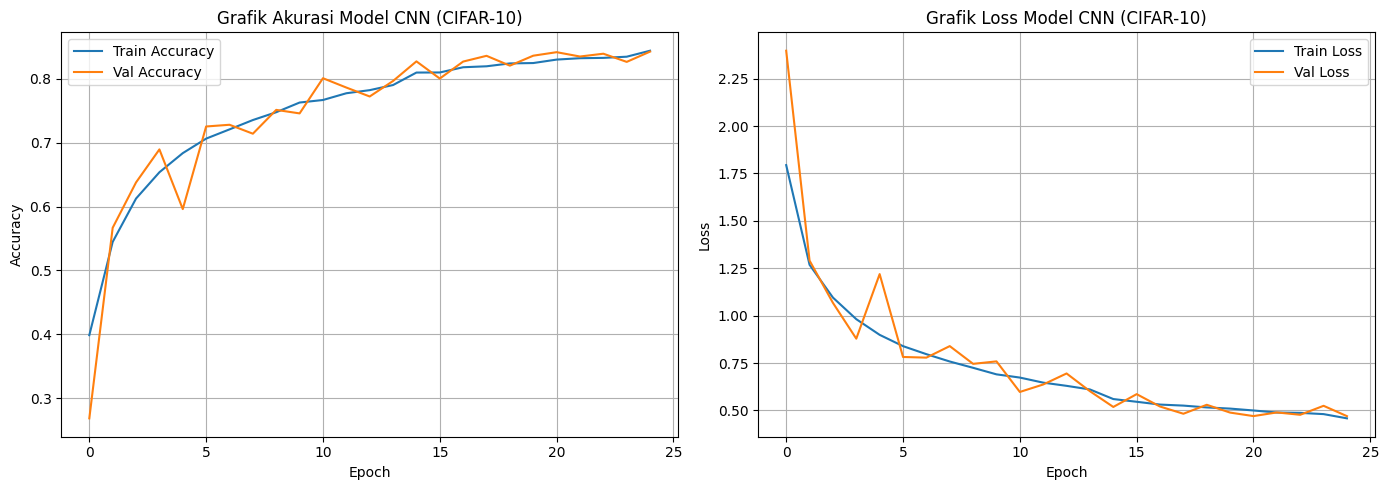


Epoch berjalan   : 25
Test Accuracy    : 0.8429 (84.29%)
Target           : > 80%
Status           : TERCAPAI


In [5]:
# Visualisasi grafik akurasi dan loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_imp.history["accuracy"], label="Train Accuracy")
ax1.plot(history_imp.history["val_accuracy"], label="Val Accuracy")
ax1.set_title("Grafik Akurasi Model CNN (CIFAR-10)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True)

ax2.plot(history_imp.history["loss"], label="Train Loss")
ax2.plot(history_imp.history["val_loss"], label="Val Loss")
ax2.set_title("Grafik Loss Model CNN (CIFAR-10)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Evaluasi performa model pada data pengujian
test_loss, test_acc = model_improved.evaluate(test_ds, verbose=0)
epoch_ran = len(history_imp.history["accuracy"])
print(f"\nEpoch berjalan   : {epoch_ran}")
print(f"Test Accuracy    : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Target           : > 80%")
print(f"Status           : {'TERCAPAI' if test_acc > 0.80 else 'Belum tercapai'}")

> Hasil evaluasi menunjukkan nilai akurasi dan loss akhir pada data pengujian CIFAR-10. Kurva akurasi dan loss menggambarkan pola konvergensi model selama proses pembelajaran.

---

# **Tugas 2 - CNN untuk Klasifikasi Dataset MNIST**

---

> **Deskripsi Tugas 2:**
>
> Bangun model CNN untuk mengklasifikasikan dataset MNIST yang berisi 70.000 gambar digit tulisan tangan (0-9) berukuran 28×28 piksel grayscale. Dataset terbagi menjadi 60.000 data training dan 10.000 data testing.

---

# **T2 - Langkah 1 - Load Dataset MNIST**

---

> Load dataset MNIST dari `tensorflow.keras.datasets`, normalisasi pixel ke [0,1], dan reshape dimensi input dari (28,28) menjadi (28,28,1) untuk menambahkan dimensi channel yang diperlukan layer `Conv2D`.

In [6]:
# Load dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalisasi dan reshape
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test  = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print("Shape train :", x_train.shape)
print("Shape test  :", x_test.shape)
print("Jumlah kelas:", len(set(y_train.flatten())))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape train : (60000, 28, 28, 1)
Shape test  : (10000, 28, 28, 1)
Jumlah kelas: 10


> MNIST berhasil dimuat: 60.000 training dan 10.000 testing. Reshape menambahkan dimensi channel (grayscale=1) yang wajib ada untuk input `Conv2D`. Normalisasi ke [0,1] mempercepat konvergensi dan menstabilkan gradien.

---

# **T2 - Langkah 2 - Visualisasi Dataset MNIST**

---

> Tampilkan 25 sampel gambar digit dari training set beserta labelnya untuk memverifikasi dataset termuat dengan benar dan distribusi kelas terlihat merata.

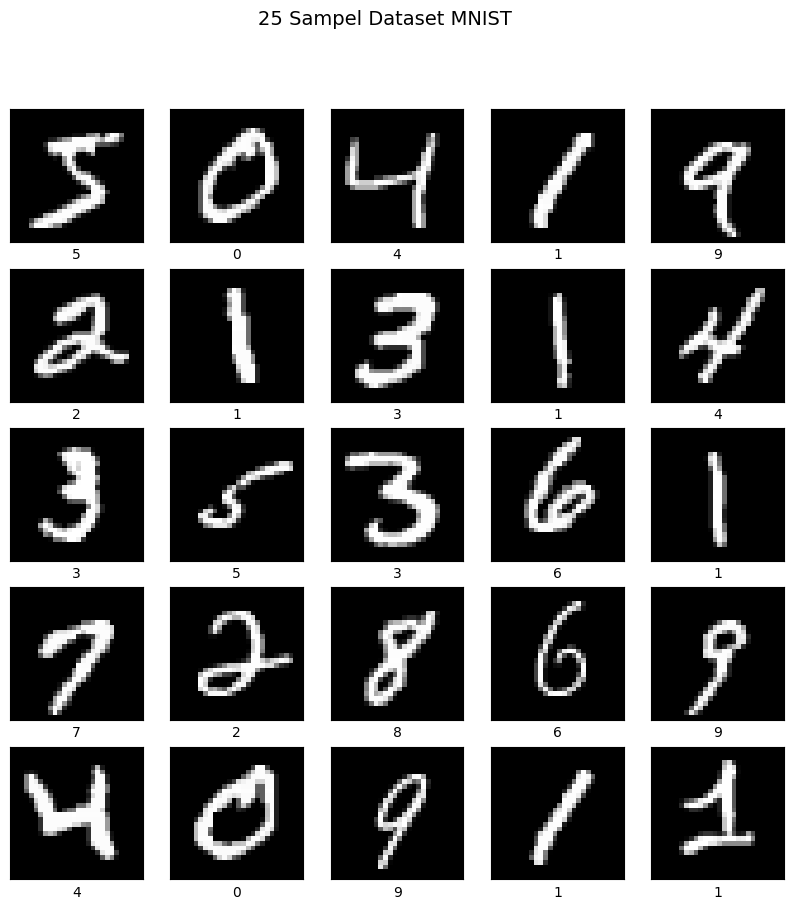

In [7]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.xlabel(str(y_train[i]))
plt.suptitle('25 Sampel Dataset MNIST', fontsize=14)
plt.show()

> Grid 5×5 menampilkan 25 sampel digit MNIST beserta label angkanya. Visualisasi ini mengonfirmasi bahwa data dimuat dengan benar dan gambar memiliki variasi tulisan tangan yang beragam untuk tiap digit.

---

# **T2 - Langkah 3 - Bangun Model CNN untuk MNIST**

---

> Bangun CNN yang dioptimalkan untuk MNIST: dua blok Conv2D + BatchNorm + MaxPool, diikuti Flatten dan Dense layer. Karena MNIST relatif sederhana dibanding CIFAR-10, arsitektur lebih ringan namun tetap mampu mencapai akurasi > 99%.

In [8]:
model_mnist = models.Sequential([
    # Blok Konvolusi 1
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(28,28,1)),
    BatchNormalization(),
    Conv2D(32, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Blok Konvolusi 2
    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Fully Connected Block
    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_mnist.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

> CNN untuk MNIST menggunakan arsitektur simetris dengan 4 Conv2D layer (32->32->64->64 filter), BatchNorm untuk stabilisasi, dan Dropout (0.25->0.5) sebagai regularisasi. Output layer `Dense(10, softmax)` menghasilkan probabilitas untuk 10 digit (0-9).

---

# **T2 - Langkah 4 - Kompilasi dan Training CNN MNIST**

---

> Kompilasi model MNIST dengan Adam optimizer, loss `sparse_categorical_crossentropy`, dan metrik `accuracy`. Latih selama 15 epoch dengan batch size 128, MNIST yang relatif sederhana umumnya konvergen cepat dalam beberapa epoch pertama.

In [9]:
model_mnist.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_mnist = model_mnist.fit(
    x_train, y_train,
    batch_size=128,
    epochs=15,
    validation_data=(x_test, y_test)
)

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 38s 47ms/step - accuracy: 0.9395 - loss: 0.1984 - val_accuracy: 0.7533 - val_loss: 0.6953
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9800 - loss: 0.0667 - val_accuracy: 0.9890 - val_loss: 0.0319
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9853 - loss: 0.0489 - val_accuracy: 0.9912 - val_loss: 0.0267
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9879 - loss: 0.0390 - val_accuracy: 0.9919 - val_loss: 0.0230
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9891 - loss: 0.0348 - val_accuracy: 0.9921 - val_loss: 0.0233
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9901 - loss: 0.0312 - val_accuracy: 0.9936 - val_loss: 0.0196
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9912 - loss: 0.0274 - val_accuracy: 0.9916 - val_loss: 0.0260
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9920 - loss: 0.0248 - val_acc

> Model MNIST dilatih dengan 60.000 sampel selama 15 epoch menggunakan batch size 128 untuk efisiensi memori dan kecepatan komputasi. Karena MNIST lebih sederhana dari CIFAR-10, model konvergen lebih cepat dengan akurasi yang lebih tinggi.

---

# **T2 - Langkah 5 - Evaluasi Model CNN MNIST**

---

> Evaluasi performa model CNN pada data test MNIST: tampilkan grafik learning curve (akurasi dan loss), cetak nilai akurasi final, dan visualisasikan beberapa prediksi beserta confusion matrix untuk analisis kesalahan klasifikasi per kelas.

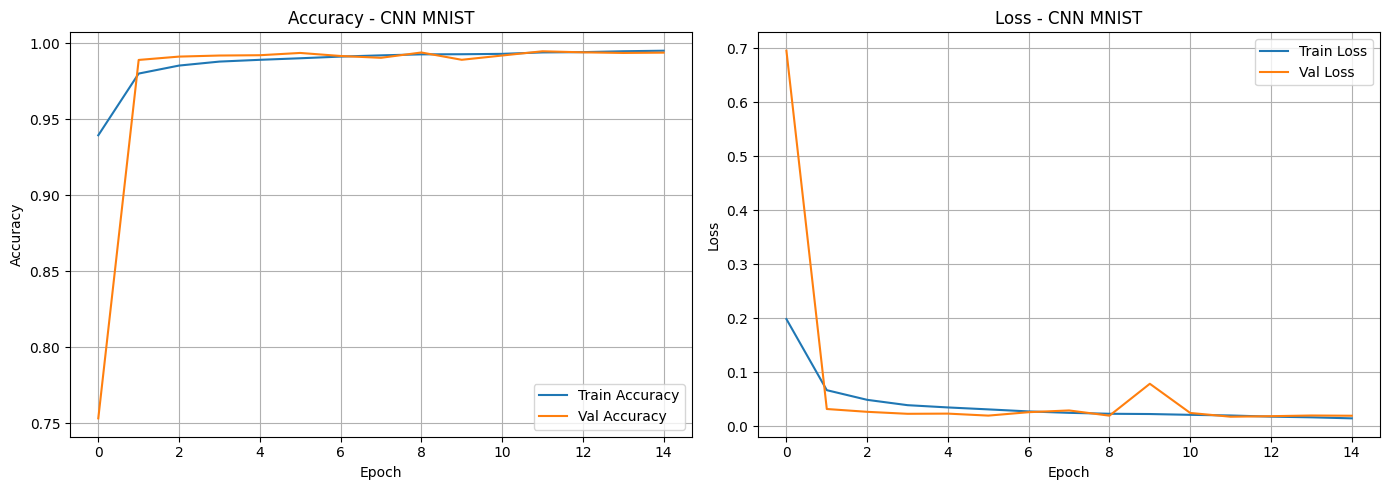


Test Loss     : 0.0194
Test Accuracy : 0.9938 (99.38%)


In [10]:
# Grafik Akurasi dan Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_mnist.history['accuracy'], label='Train Accuracy')
ax1.plot(history_mnist.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Accuracy - CNN MNIST')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(history_mnist.history['loss'], label='Train Loss')
ax2.plot(history_mnist.history['val_loss'], label='Val Loss')
ax2.set_title('Loss - CNN MNIST')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Evaluasi final
test_loss_m, test_acc_m = model_mnist.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Loss     : {test_loss_m:.4f}")
print(f"Test Accuracy : {test_acc_m:.4f} ({test_acc_m*100:.2f}%)")

> Grafik learning curve menampilkan konvergensi model CNN pada dataset MNIST. CNN umumnya mencapai akurasi 99%+ pada MNIST berkat kemampuan ekstraksi fitur spatial yang unggul dibandingkan MLP biasa, terutama untuk pola digit tulisan tangan.

---

# **T2 - Langkah 6 - Visualisasi Prediksi MNIST**

---

> Tampilkan 25 prediksi model pada test set MNIST: gambar dengan prediksi benar diberi judul hitam, sedangkan prediksi salah diberi judul merah dengan format `prediksi(actual)` untuk memudahkan identifikasi kesalahan klasifikasi.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


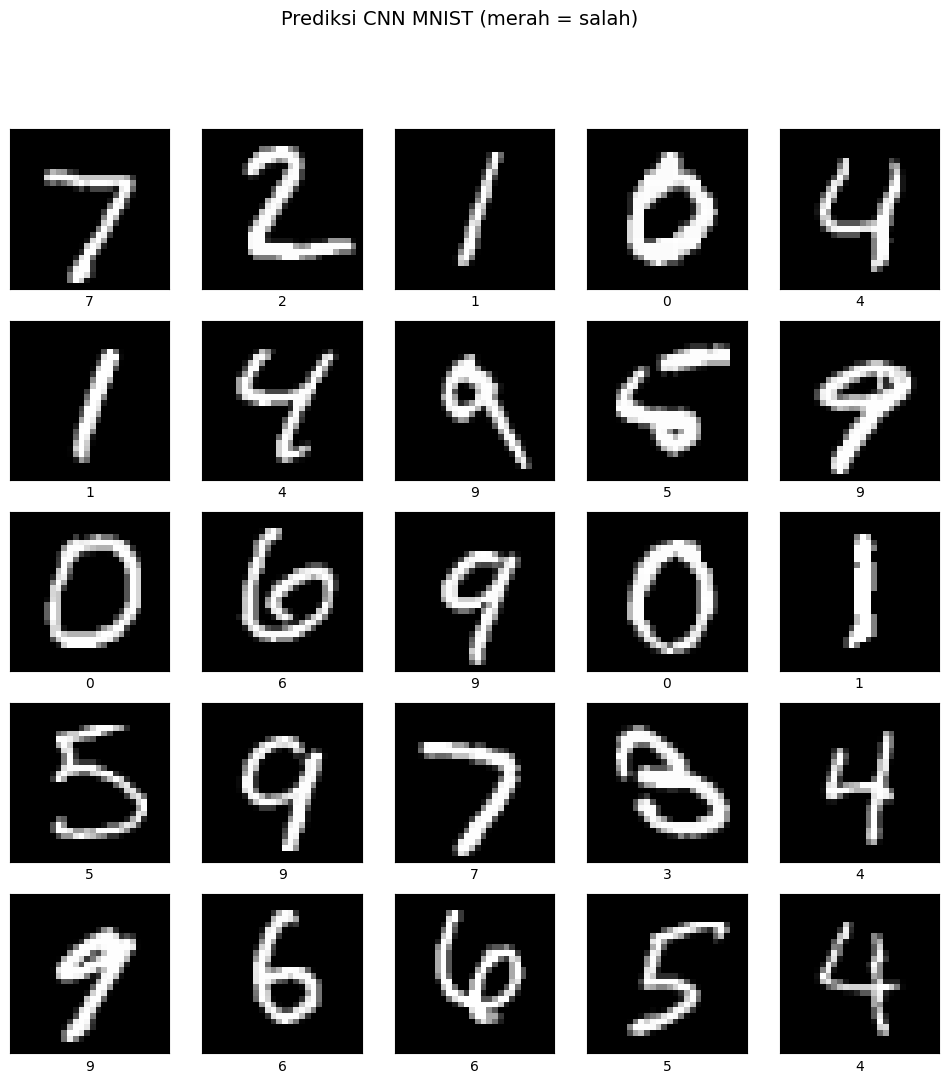


Akurasi per kelas:
  Digit 0: 99.80%
  Digit 1: 99.91%
  Digit 2: 99.81%
  Digit 3: 99.50%
  Digit 4: 99.08%
  Digit 5: 99.78%
  Digit 6: 99.48%
  Digit 7: 97.86%
  Digit 8: 99.49%
  Digit 9: 99.11%


In [11]:
# Prediksi seluruh test set
predictions = model_mnist.predict(x_test)
pred_labels = np.argmax(predictions, axis=1)

# Visualisasi 25 prediksi
plt.figure(figsize=(12, 12))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    pred = pred_labels[i]
    actual = y_test[i]
    color = 'black' if pred == actual else 'red'
    plt.xlabel(f'{pred}' if pred == actual else f'{pred}({actual})', color=color)
plt.suptitle('Prediksi CNN MNIST (merah = salah)', fontsize=14)
plt.show()

# Hitung akurasi per kelas
from collections import Counter
correct_per_class = Counter()
total_per_class = Counter()
for pred, actual in zip(pred_labels, y_test):
    total_per_class[actual] += 1
    if pred == actual:
        correct_per_class[actual] += 1

print("\nAkurasi per kelas:")
for c in range(10):
    acc_c = correct_per_class[c] / total_per_class[c]
    print(f"  Digit {c}: {acc_c*100:.2f}%")

> Visualisasi prediksi menampilkan gambar test dengan label prediksi. Judul merah menandai kesalahan klasifikasi beserta label aktualnya. Akurasi per kelas menunjukkan digit mana yang paling sulit diklasifikasikan oleh model, berguna untuk analisis lebih lanjut.